# Choosing interface smoothing

Start with `RasterOptions(smoothing="farjadpour_diagonal")`, the default. Compare it with
`"farjadpour_full"` at your working grid and switch if the observable you care about differs
by more than your tolerance. Curved coupling gaps and multimode conversion are useful cases
to check; single-mode bends often benefit more from mesh refinement.

This tutorial compares a 500 × 220 nm silicon U-bend with a pair of those bends forming a
curved coupler. `"volume"` arithmetic averaging is included as a baseline.


## Setup

In [1]:
import gc
import os

import jax
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Ellipse, FancyArrowPatch, Polygon, Rectangle

import beamz as bz
from beamz.design.raster import RasterOptions

test_mode = os.environ.get("BEAMZ_DOCS_TEST") == "1"
um = bz.um
on_gpu = jax.default_backend() == "gpu"
print("JAX backend:", jax.default_backend())

JAX backend: gpu


## What each method assigns to a cut cell

At a flat wall the field component **along** the wall sees the *arithmetic* mean of the two
permittivities. The component **across** the wall sees the *harmonic* mean, because the normal
component of D is continuous. With core fill fraction $f$ and wall normal $\mathbf{n}$, the exact
cell value is the tensor
([Farjadpour et al. 2006](https://doi.org/10.1364/OL.31.002972), [Kottke et al. 2008](https://doi.org/10.1103/PhysRevE.77.036611)):

$$
\varepsilon_\text{exact} = \varepsilon_\text{harm}\,\mathbf{n}\mathbf{n}^\mathsf{T} + \varepsilon_\text{arith}\,(\mathbf{I}-\mathbf{n}\mathbf{n}^\mathsf{T}),\qquad
\varepsilon_\text{arith} = f\varepsilon_1+(1-f)\varepsilon_2,\quad
\varepsilon_\text{harm} = \Big(\tfrac{f}{\varepsilon_1}+\tfrac{1-f}{\varepsilon_2}\Big)^{-1}.
$$

- `volume` uses $\varepsilon_\text{arith}$ in every direction.
- `farjadpour_diagonal` keeps only the diagonal ($\varepsilon_{xx},\varepsilon_{yy},\varepsilon_{zz}$) of $\varepsilon_\text{exact}$.
- `farjadpour_full` keeps the whole tensor, including $\varepsilon_{xy}$, $\varepsilon_{xz}$ and $\varepsilon_{yz}$.

Below, each tensor is drawn as an ellipse in a half-filled cell. The long axis is the direction
of larger ε, and the dashed ellipse is exact. The bottom row shows what the $E_x$ update reads.
That is where full tensor's extra cost comes from: it also reads the neighbouring $D_y$ (and $D_z$).

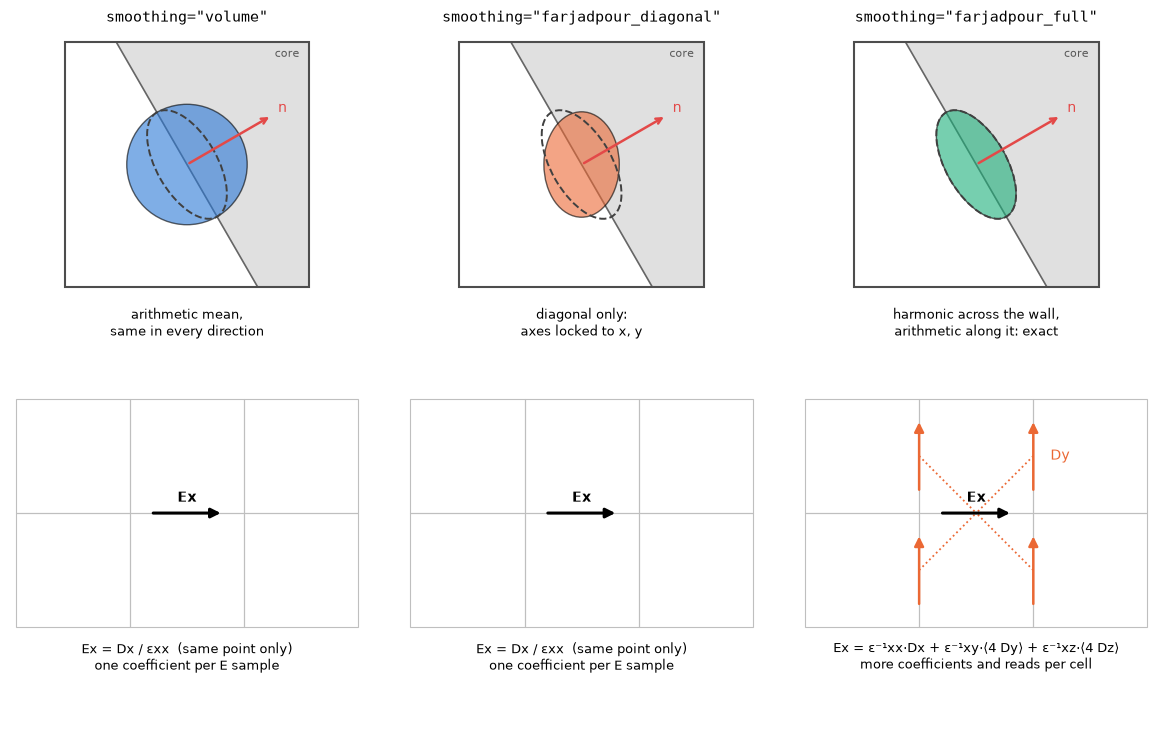

In [2]:
eps_core, eps_clad = 3.48**2, 1.444**2  # silicon in oxide, as in the U-bend below
f0, theta = 0.5, 30.0                  # half-filled cell, wall normal 30 degrees from x
n = np.array([np.cos(np.radians(theta)), np.sin(np.radians(theta))])
t = np.array([-n[1], n[0]])
arith = f0 * eps_core + (1 - f0) * eps_clad
harm = 1 / (f0 / eps_core + (1 - f0) / eps_clad)
exact = harm * np.outer(n, n) + arith * np.outer(t, t)
methods = {
    "volume": (np.eye(2) * arith, "#2a78d6", "arithmetic mean,\nsame in every direction"),
    "farjadpour_diagonal": (np.diag(np.diag(exact)), "#eb6834", "diagonal only:\naxes locked to x, y"),
    "farjadpour_full": (exact, "#1baf7a", "harmonic across the wall,\narithmetic along it: exact"),
}
scale = 0.42 / eps_core

def draw_ellipse(ax, tensor, **kw):
    w, v = np.linalg.eigh(tensor)
    angle = np.degrees(np.arctan2(v[1, 1], v[0, 1]))
    ax.add_patch(Ellipse((0, 0), 2 * scale * w[1], 2 * scale * w[0], angle=angle, **kw))

fig, axs = plt.subplots(2, 3, figsize=(12, 7.5))
for ax, (name, (tensor, color, note)) in zip(axs[0], methods.items()):
    clip = Rectangle((-0.5, -0.5), 1, 1, transform=ax.transData)
    core = Polygon([3 * t, 3 * t + 3 * n, -3 * t + 3 * n, -3 * t], color="0.88", zorder=0)
    ax.add_patch(core)
    core.set_clip_path(clip)
    wall, = ax.plot(*np.c_[-3 * t, 3 * t], color="0.4", lw=1.2)
    wall.set_clip_path(clip)
    ax.add_patch(Rectangle((-0.5, -0.5), 1, 1, fill=False, lw=1.5, ec="0.3", zorder=6))
    draw_ellipse(ax, tensor, fc=color, alpha=0.6, ec="k", lw=1, zorder=2)
    draw_ellipse(ax, exact, fill=False, ls="--", lw=1.4, ec="0.25", zorder=3)
    ax.annotate("", 0.4 * n, (0, 0), arrowprops=dict(arrowstyle="->", color="#e34948", lw=1.8))
    ax.text(*(0.43 * n), "n", color="#e34948")
    ax.text(0.46, 0.44, "core", ha="right", fontsize=8, color="0.35")
    ax.text(0, -0.58, note, ha="center", va="top", fontsize=9.5)
    ax.set(xlim=(-0.55, 0.55), ylim=(-0.85, 0.55), aspect="equal", xticks=[], yticks=[])
    ax.set_title(f'smoothing="{name}"', fontsize=11, family="monospace")
    for spine in ax.spines.values():
        spine.set_visible(False)

def edge_arrow(ax, xy, direction, color, lw=2.2):
    xy, d = np.asarray(xy, float), 0.32 * np.asarray(direction, float)
    ax.add_patch(FancyArrowPatch(xy - d, xy + d, arrowstyle="-|>", mutation_scale=14, color=color, lw=lw, zorder=5))

for ax, name in zip(axs[1], methods):
    for x in range(3):
        for y in range(2):
            ax.add_patch(Rectangle((x, y), 1, 1, fill=False, ec="0.75", lw=0.8))
    edge_arrow(ax, (1.5, 1.0), (1, 0), "k")
    ax.text(1.5, 1.1, "Ex", ha="center", fontweight="bold")
    if name == "farjadpour_full":
        for d in [(1, 0.5), (2, 0.5), (1, 1.5), (2, 1.5)]:
            edge_arrow(ax, d, (0, 1), "#eb6834", lw=1.8)
            ax.plot(*np.c_[d, (1.5, 1.0)], ls=":", color="#eb6834", lw=1.3)
        ax.text(2.15, 1.5, "Dy", color="#eb6834", va="center")
        text = "Ex = ε⁻¹xx·Dx + ε⁻¹xy·⟨4 Dy⟩ + ε⁻¹xz·⟨4 Dz⟩\nmore coefficients and reads per cell"
    else:
        text = "Ex = Dx / εxx  (same point only)\none coefficient per E sample"
    ax.text(1.5, -0.12, text, ha="center", va="top", fontsize=9)
    ax.set(xlim=(-0.05, 3.05), ylim=(-0.9, 2.1), aspect="equal", xticks=[], yticks=[])
    for spine in ax.spines.values():
        spine.set_visible(False)
fig.tight_layout()
plt.show()

Diagonal smoothing gets the size of the tensor right, but its axes are locked to the grid.
It matches the exact tensor only when the wall lies along x, y or z. A bend sweeps the wall
normal through every angle, so diagonal smoothing is exact on the straight sections and
approximate around the curve.

## The test structure: a silicon U-bend

A 500 × 220 nm silicon strip in oxide turns through 180° with a 2 µm radius. The input and
output mode monitors sit at the same x, so their ratio
$S_{21} = a_\text{out}^- / a_\text{in}^+$ measures the bend alone. We track two observables:

- $|S_{21}|^2$, the bend transmission;
- $\arg S_{21}$, the phase through the bend. This sets where a ring resonates, so a phase error
  shows up directly as a resonance-wavelength error.

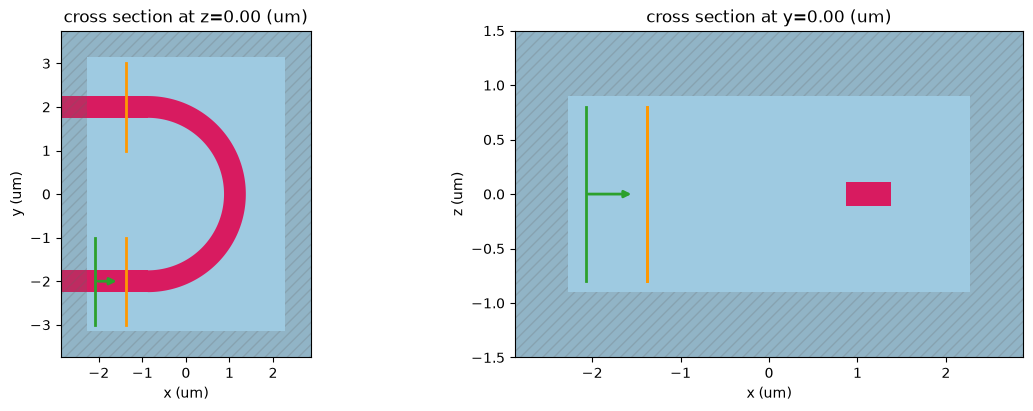

In [3]:
n_si, n_ox = 3.48, 1.444
W, H, R = 0.5 * um, 0.22 * um, 2.0 * um
lambda0 = 1.55 * um
freq0 = bz.LIGHT_SPEED / lambda0
pml = 0.6 * um
lead, margin = 1.4 * um, 0.9 * um
x_left, x_right = -lead, R + W / 2 + margin
y_bot, y_top = -margin - W / 2, 2 * R + W / 2 + margin
domain = (x_right - x_left + 2 * pml, y_top - y_bot + 2 * pml, 3.0 * um)
cx, cy = 0.5 * (x_left + x_right), 0.5 * (y_bot + y_top)  # shift to a centred domain


def make_sim(resolution, smoothing, run_time=700e-15):
    si, ox = bz.Material(permittivity=n_si**2), bz.Material(permittivity=n_ox**2)
    design = bz.Design(background=ox)
    xa = -0.5 * domain[0]
    for yc in (0.0, 2 * R):  # input and output straights
        y0 = yc - cy
        design += bz.Polygon(
            vertices=((xa, y0 - W / 2), (-cx, y0 - W / 2), (-cx, y0 + W / 2), (xa, y0 + W / 2)),
            material=si, depth=H, z=-H / 2,
        )
    design += bz.CircularBend(
        position=(-cx, R - cy), inner_radius=R - W / 2, outer_radius=R + W / 2,
        angle=180, rotation=-90, points=256, material=si, depth=H, z=-H / 2,
    )
    mode_spec = bz.ModeSpec(num_modes=1, mode_index=0, target_neff=n_si, polarization="te")
    plane = (0.0, 2.0 * um, 1.6 * um)
    source_x, monitor_x = x_left + 0.2 * um - cx, x_left + 0.9 * um - cx
    source = bz.ModeSource(
        center=(source_x, -cy, 0.0), size=plane, direction="+", mode_spec=mode_spec,
        source_time=bz.GaussianPulse(freq0=freq0, fwidth=0.1 * freq0),
    )
    monitors = (
        bz.ModeMonitor(center=(monitor_x, -cy, 0.0), size=plane, freqs=[freq0], mode_spec=mode_spec, name="mode_in"),
        bz.ModeMonitor(center=(monitor_x, 2 * R - cy, 0.0), size=plane, freqs=[freq0], mode_spec=mode_spec, name="mode_out"),
    )
    return bz.Simulation(
        domain=domain, design=design, sources=(source,), monitors=monitors,
        boundaries=(bz.PML(thickness=pml, formulation="cpml"),),
        grid_spec=bz.GridSpec.uniform(resolution), run_time=run_time,
        raster_options=RasterOptions(smoothing=smoothing),
    )


def s21(results):
    a_in = complex(np.asarray(results.mode("mode_in").amps.sel(direction="+")).ravel()[0])
    a_out = complex(np.asarray(results.mode("mode_out").amps.sel(direction="-")).ravel()[0])
    return a_out / a_in


preview = make_sim(50e-9, "farjadpour_full")
fig, axes = preview.plot(z=0.0, show=False)
plt.show()

## What BEAMZ actually stores

`Design.rasterize(resolution, smoothing=...)` returns the material grid the solver uses.
Diagonal and volume smoothing store one value per E component (`yee_materials["eps_x"]` and so
on). Full smoothing stores all six tensor components (`yee_tensors`, ordered xx, yy, zz, xy, xz, yz).

The maps below show the core mid-plane around the bend: full tensor's $\varepsilon_{xx}$, how
volume and diagonal differ from it, and full tensor's $\varepsilon_{xy}$. Volume differs on every
cut cell. Diagonal's $\varepsilon_{xx}$ is **identical** to full tensor's: diagonal keeps the diagonal
exactly. What it drops is $\varepsilon_{xy}$ (right), which is nonzero only where the wall is oblique to the grid.

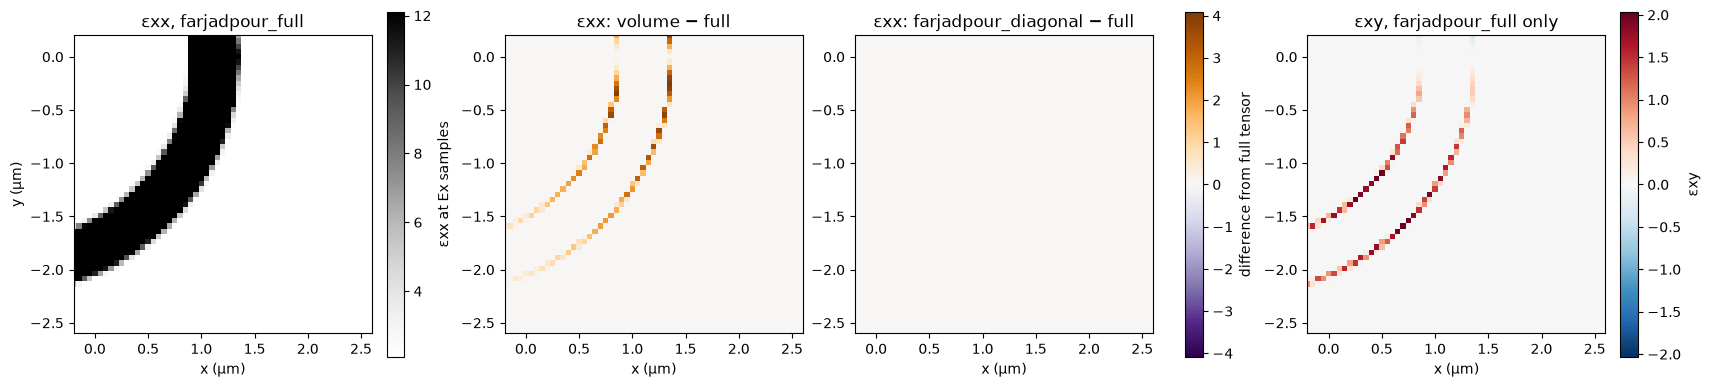

largest |εxy| = 2.04; zero in every cell whose wall is along x or y


In [4]:
res_map = 50e-9
grids = {name: preview.design.rasterize(res_map, smoothing=name) for name in methods}
mid = grids["farjadpour_full"].shape[0] // 2  # storage order is (z, y, x)
eps_xx = {
    "volume": np.asarray(grids["volume"].yee_materials["eps_x"])[mid],
    "farjadpour_diagonal": np.asarray(grids["farjadpour_diagonal"].yee_materials["eps_x"])[mid],
    "farjadpour_full": np.asarray(grids["farjadpour_full"].yee_tensors["eps_x"])[0, mid],
}
eps_xy = np.asarray(grids["farjadpour_full"].yee_tensors["eps_x"])[3, mid]
extent = (-domain[0] / 2 / um, domain[0] / 2 / um, -domain[1] / 2 / um, domain[1] / 2 / um)
zoom = dict(xlim=(-0.2, 2.6), ylim=(-2.6, 0.2))  # lower-right quarter of the bend

fig, axs = plt.subplots(1, 4, figsize=(17, 4.4), constrained_layout=True)
image = axs[0].imshow(eps_xx["farjadpour_full"], origin="lower", extent=extent, cmap="Greys", vmin=eps_clad, vmax=eps_core)
axs[0].set(title="εxx, farjadpour_full", xlabel="x (µm)", ylabel="y (µm)", **zoom)
fig.colorbar(image, ax=axs[0], shrink=0.8, label="εxx at Ex samples")
diff_lim = max(np.abs(eps_xx[k] - eps_xx["farjadpour_full"]).max() for k in ("volume", "farjadpour_diagonal"))
for ax, name in zip(axs[1:3], ("volume", "farjadpour_diagonal")):
    image = ax.imshow(eps_xx[name] - eps_xx["farjadpour_full"], origin="lower", extent=extent, cmap="PuOr_r",
                      vmin=-diff_lim, vmax=diff_lim)
    ax.set(title=f"εxx: {name} − full", xlabel="x (µm)", **zoom)
fig.colorbar(image, ax=axs[1:3], shrink=0.8, label="difference from full tensor")
lim = np.abs(eps_xy).max()
image = axs[3].imshow(eps_xy, origin="lower", extent=extent, cmap="RdBu_r", vmin=-lim, vmax=lim)
axs[3].set(title="εxy, farjadpour_full only", xlabel="x (µm)", **zoom)
fig.colorbar(image, ax=axs[3], shrink=0.8, label="εxy")
plt.show()
print(f"largest |εxy| = {lim:.2f}; zero in every cell whose wall is along x or y")

## Memory before you run

`Simulation.memory_estimate()` estimates persistent fields, material grids and CPML without
running the solver. In BEAMZ 0.5.3 it omits full-tensor coefficient arrays, so its total does
not distinguish smoothing methods. Leave headroom and measure actual GPU use.

For this bend, separate GPU runs peaked at 0.78 / 0.87 GB for diagonal / full at 30 nm,
and 2.48 / 3.06 GB at 20 nm. Full tensor saves memory when it permits a coarser grid.


In [5]:
report = make_sim(25e-9, "farjadpour_diagonal").memory_estimate()
print(f"estimated persistent memory at 25 nm: {report['total_gib']:.2f} GiB")
display(pd.Series(report["totals_by_category"]).div(2**30).round(3).rename("GiB"))

estimated persistent memory at 25 nm: 0.59 GiB


yee_fields                  0.187
material_center_grids       0.123
component_material_grids    0.280
pml_data                    0.000
Name: GiB, dtype: float64

## Does the choice matter here?

We run each method on the same sequence of grids, 60 to 30 nm, and record $S_{21}$. On a GPU
the sweep takes a few minutes, with peak memory below 1 GB. With `BEAMZ_DOCS_TEST=1`, two coarse grids
run on CPU for a quick check. Run time is BEAMZ's synchronized execution time, with setup and JIT excluded.

In [6]:
grid_nm = (80, 60) if test_mode else (60, 50, 40, 30)
colors = {name: style[1] for name, style in methods.items()}
markers = {"volume": "o", "farjadpour_diagonal": "s", "farjadpour_full": "D"}
records = []
for nm in grid_nm:
    for name in methods:
        sim = make_sim(nm * 1e-9, name)
        results = sim.run()
        value = s21(results)
        perf = getattr(results, "performance", None)
        records.append(dict(smoothing=name, grid_nm=nm, cells_M=np.prod(sim.grid.shape) / 1e6,
                            T=abs(value) ** 2, phase=np.angle(value),
                            seconds=getattr(perf, "runtime_s", np.nan)))
        del sim, results          # release device buffers before the next case
        jax.clear_caches()
        gc.collect()
data = pd.DataFrame(records)
display(data.round(4))

Simulation runtime: 1.32 s
GCUPS: 2.782


Simulation runtime: 1.28 s
GCUPS: 2.866


Simulation runtime: 2.54 s
GCUPS: 1.443


Simulation runtime: 3.32 s
GCUPS: 2.287


Simulation runtime: 3.33 s
GCUPS: 2.279


...

Simulation runtime: 14.18 s
GCUPS: 1.314


Simulation runtime: 30.27 s
GCUPS: 1.941


Simulation runtime: 30.18 s
GCUPS: 1.947


Simulation runtime: 46.45 s
GCUPS: 1.265


,smoothing,grid_nm,cells_M,T,phase,seconds
0,volume,60,0.6000,0.9682,0.1508,1.3198
1,farjadpour_diagonal,60,0.6000,0.9792,0.9328,1.2813
2,farjadpour_full,60,0.6000,0.9805,1.0986,2.5447
3,volume,50,1.0350,0.9723,0.2472,3.3241
4,farjadpour_diagonal,50,1.0350,0.9790,0.6964,3.3348
5,farjadpour_full,50,1.0350,0.9800,0.8107,5.3033
6,volume,40,2.0304,0.9750,0.2429,9.4718
7,farjadpour_diagonal,40,2.0304,0.9794,0.6162,9.4853
8,farjadpour_full,40,2.0304,0.9801,0.7199,14.1848
9,volume,30,4.8000,0.9757,0.2245,30.2697


### Separate grid dispersion from the wall treatment

The phase through the bend has two error sources:

- **Grid dispersion.** The Yee grid slightly misrepresents the propagation constant everywhere
  along the ~9 µm path. It shrinks only with a finer grid.
- **The wall treatment.** This is the part the smoothing choice controls.

Diagonal and full treat the straight sections identically and share the same dispersion. So the
difference between them **at the same grid** isolates the effect of the bend wall treatment.

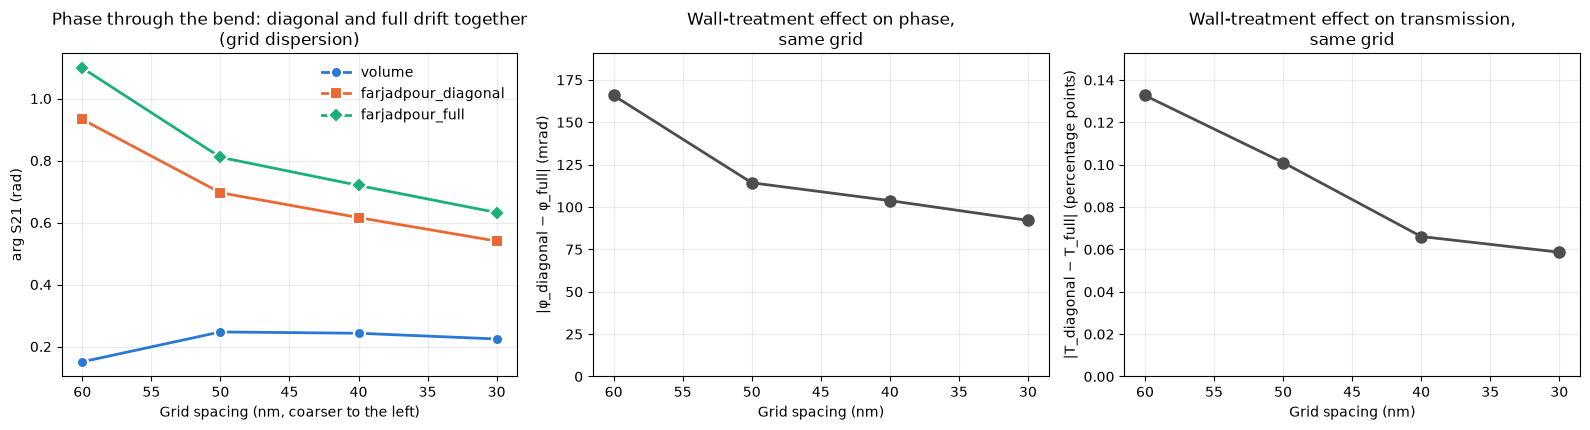

,|Δphase| (mrad),|ΔT| (pp),full / diagonal run time
grid_nm,,,
30,92.1,0.059,1.54
40,103.8,0.066,1.50
50,114.3,0.101,1.59
60,165.8,0.133,1.99


In [7]:
pivot = {q: data.pivot(index="grid_nm", columns="smoothing", values=q) for q in ("phase", "T", "seconds", "cells_M")}
fig, axs = plt.subplots(1, 3, figsize=(16, 4.4))
for name in methods:
    if name in pivot["phase"]:
        axs[0].plot(pivot["phase"].index, pivot["phase"][name], marker=markers[name], color=colors[name],
                    lw=2, ms=8, mec="white", mew=1.5, label=name)
axs[0].set(xlabel="Grid spacing (nm, coarser to the left)", ylabel="arg S21 (rad)",
           title="Phase through the bend: diagonal and full drift together\n(grid dispersion)")
axs[0].invert_xaxis()
axs[0].legend(frameon=False)
dphi = pd.Series(1e3 * np.angle(np.exp(1j * (pivot["phase"]["farjadpour_diagonal"] - pivot["phase"]["farjadpour_full"]))),
                 index=pivot["phase"].index)
dT = 100 * (pivot["T"]["farjadpour_diagonal"] - pivot["T"]["farjadpour_full"])
axs[1].plot(dphi.index, dphi.abs(), "o-", color="0.3", lw=2, ms=8)
axs[1].set_ylim(0, 1.15 * dphi.abs().max())
axs[1].set(xlabel="Grid spacing (nm)", ylabel="|φ_diagonal − φ_full| (mrad)",
           title="Wall-treatment effect on phase,\nsame grid")
axs[1].invert_xaxis()
axs[2].plot(dT.index, dT.abs(), "o-", color="0.3", lw=2, ms=8)
axs[2].set_ylim(0, 1.15 * dT.abs().max())
axs[2].set(xlabel="Grid spacing (nm)", ylabel="|T_diagonal − T_full| (percentage points)",
           title="Wall-treatment effect on transmission,\nsame grid")
axs[2].invert_xaxis()
for ax in axs:
    ax.grid(True, alpha=0.25)
fig.tight_layout()
plt.show()

cost = (pivot["seconds"]["farjadpour_full"] / pivot["seconds"]["farjadpour_diagonal"]).round(2)
display(pd.DataFrame({"|Δphase| (mrad)": dphi.abs().round(1), "|ΔT| (pp)": dT.abs().round(3),
                      "full / diagonal run time": cost}))

### Reading the result

Diagonal and full differ by about 0.1 pp in transmission and 0.1 rad in phase on coarse grids.
A separate 20 nm run reduced those differences to 0.05 pp and 65 mrad. From 60 to 30 nm,
grid refinement moves their phases by 390–470 mrad, so mesh density matters more here.
Volume's nearly stationary phase is cancellation between wall and grid errors, not evidence
of accuracy. Full costs roughly 1.5–2× the GPU time per grid in the separate measurements.

For this single-mode bend, keep diagonal and refine the grid. A phase error of 0.1 rad would
shift a ring resonance by about 1.6% of a free spectral range.


## When full tensor pays off: a curved coupler

In the U-bend, light travels along the walls, and diagonal smoothing only nudges the phase. In a
coupler, the power that crosses the gap is set by the evanescent fields at the two facing walls.
Around a curved gap the walls are grid-aligned only at the apex. On either side, while the guides
are still close enough to couple, they are oblique, which is exactly where diagonal smoothing
drops $\varepsilon_{xy}$. The coupled power is also small, so a small field error becomes a large
relative error.

The test structure is two of the U-bends above placed back to back (⊃⊂), like the point coupler of
a ring: the same 500 × 220 nm silicon strip and R = 2 µm, with a 200 nm gap at closest approach.
TE0 enters the lower-left port. Most of the light stays in the left bend and leaves through the
upper-left port (`bar`). The rest crosses the gap and leaves through the upper-right port (`cross`).
We track the cross power $|S_\text{cross}|^2 = \kappa^2$, which sets a ring's coupling.

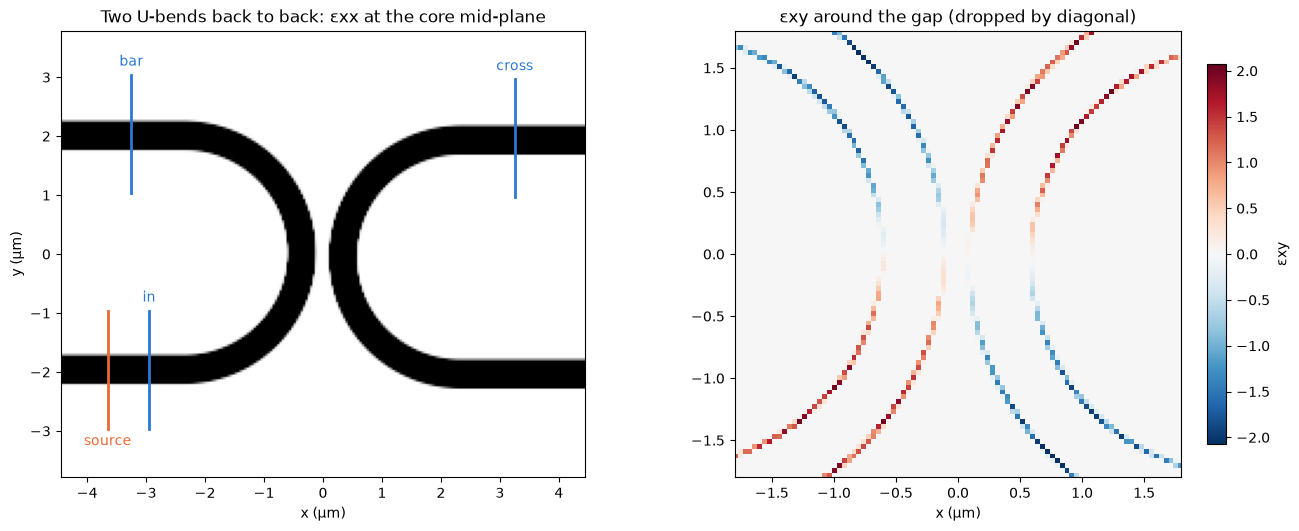

In [8]:
gap, c_lead = 0.2 * um, 1.5 * um
arc = np.linspace(-np.pi / 2, np.pi / 2, 96)  # polygon vertices on each 180° arc


def bend_edge(r):
    # One wall of the left U-bend, bend centre at the origin: lower lead, arc, upper lead.
    far = -c_lead - 12 * um  # leads continue through the PML
    return np.r_[[[far, -r]], np.c_[r * np.cos(arc), r * np.sin(arc)], [[far, r]]]


left = np.r_[bend_edge(R + W / 2), bend_edge(R - W / 2)[::-1]]
# The gap is set at the arc vertex nearest the apex. The right U-bend is the left one
# rotated 180° about the gap centre, so all four ports run along x.
apex = arc[np.argmin(np.abs(arc))]
gap_centre = (R + (W + gap) / 2) * np.array([np.cos(apex), np.sin(apex)])
right = 2 * gap_centre - left
coupler_ports = {"in": (-c_lead, -R), "bar": (-c_lead, R), "cross": tuple(2 * gap_centre - (-c_lead, -R))}
y_lo, y_hi = min(-R, 2 * gap_centre[1] - R), max(R, 2 * gap_centre[1] + R)
y_margin = W / 2 + margin
coupler_origin = np.array([gap_centre[0], (y_lo + y_hi) / 2])  # becomes the domain centre
coupler_domain = (2 * (gap_centre[0] + c_lead) + 2 * pml, y_hi - y_lo + 2 * y_margin + 2 * pml, 3.0 * um)


def make_coupler(resolution, smoothing, run_time=900e-15):
    si, ox = bz.Material(permittivity=n_si**2), bz.Material(permittivity=n_ox**2)
    design = bz.Design(background=ox)
    for outline in (left, right):
        design += bz.Polygon(vertices=tuple(map(tuple, outline - coupler_origin)), material=si, depth=H, z=-H / 2)
    mode_spec = bz.ModeSpec(num_modes=1, mode_index=0, target_neff=n_si, polarization="te")
    plane = (0.0, 2.0 * um, 1.6 * um)
    xy = {name: np.subtract(p, coupler_origin) for name, p in coupler_ports.items()}
    source = bz.ModeSource(
        center=(xy["in"][0] + 0.2 * um, xy["in"][1], 0.0), size=plane, direction="+", mode_spec=mode_spec,
        source_time=bz.GaussianPulse(freq0=freq0, fwidth=0.1 * freq0),
    )

    def port(name, dx):
        return bz.ModeMonitor(center=(xy[name][0] + dx, xy[name][1], 0.0), size=plane, freqs=[freq0],
                              mode_spec=mode_spec, name=name)

    return bz.Simulation(
        domain=coupler_domain, design=design, sources=(source,),
        monitors=(port("in", 0.9 * um), port("bar", 0.6 * um), port("cross", -0.6 * um)),
        boundaries=(bz.PML(thickness=pml, formulation="cpml"),),
        grid_spec=bz.GridSpec.uniform(resolution), run_time=run_time,
        raster_options=RasterOptions(smoothing=smoothing),
    )


def coupler_s(results):
    amp = lambda name, d: complex(np.asarray(results.mode(name).amps.sel(direction=d)).ravel()[0])
    a_in = amp("in", "+")
    return amp("cross", "+") / a_in, amp("bar", "-") / a_in  # bar light travels back along -x


coupler_preview = make_coupler(40e-9, "farjadpour_full")
tensor = np.asarray(coupler_preview.design.rasterize(40e-9, smoothing="farjadpour_full").yee_tensors["eps_x"])
k = tensor.shape[1] // 2  # core mid-plane
c_extent = (-coupler_domain[0] / 2 / um, coupler_domain[0] / 2 / um, -coupler_domain[1] / 2 / um, coupler_domain[1] / 2 / um)

fig, axs = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw=dict(width_ratios=[1.25, 1]), constrained_layout=True)
axs[0].imshow(tensor[0, k], origin="lower", extent=c_extent, cmap="Greys", vmin=eps_clad, vmax=eps_core)
half = np.array(coupler_domain[:2]) / 2  # stored centres are measured from the domain corner
for item, color in [(coupler_preview.sources[0], "#eb6834"), *[(m, "#2a78d6") for m in coupler_preview.monitors]]:
    x, y = (np.array(item.center[:2]) - half) / um
    is_source = item is coupler_preview.sources[0]
    axs[0].plot([x, x], [y - 1, y + 1], color=color, lw=2)
    axs[0].text(x, y - 1.1 if is_source else y + 1.1, "source" if is_source else item.name,
                ha="center", va="top" if is_source else "bottom", color=color)
axs[0].set(title="Two U-bends back to back: εxx at the core mid-plane", xlabel="x (µm)", ylabel="y (µm)")
lim = np.abs(tensor[3, k]).max()
image = axs[1].imshow(tensor[3, k], origin="lower", extent=c_extent, cmap="RdBu_r", vmin=-lim, vmax=lim)
axs[1].set(title="εxy around the gap (dropped by diagonal)", xlabel="x (µm)", xlim=(-1.8, 1.8), ylim=(-1.8, 1.8))
fig.colorbar(image, ax=axs[1], shrink=0.85, label="εxy")
plt.show()
del coupler_preview, tensor

$\varepsilon_{xy}$ vanishes at the apex, where both walls are briefly vertical, and grows on either
side while the guides are still within coupling range.

We run diagonal and full at 40 and 30 nm. On a GPU the four runs take about 4 minutes, with peak
memory below 1.5 GB. With `BEAMZ_DOCS_TEST=1`, one 80 nm grid runs on CPU.

In [9]:
coupler_grid_nm = (80,) if test_mode else (40, 30)
pair = ("farjadpour_diagonal", "farjadpour_full")
coupler_records = []
for nm in coupler_grid_nm:
    for name in pair:
        sim = make_coupler(nm * 1e-9, name)
        results = sim.run()
        cross, bar = coupler_s(results)
        perf = getattr(results, "performance", None)
        coupler_records.append(dict(smoothing=name, grid_nm=nm, cells_M=np.prod(sim.grid.shape) / 1e6,
                                    cross_pct=100 * abs(cross) ** 2, bar_pct=100 * abs(bar) ** 2,
                                    seconds=getattr(perf, "runtime_s", np.nan)))
        del sim, results          # release device buffers before the next case
        jax.clear_caches()
        gc.collect()
coupler_data = pd.DataFrame(coupler_records)
display(coupler_data.round(4))

Simulation runtime: 19.52 s
GCUPS: 1.922


Simulation runtime: 30.52 s
GCUPS: 1.229


Simulation runtime: 70.55 s
GCUPS: 1.676


Simulation runtime: 97.75 s
GCUPS: 1.210


,smoothing,grid_nm,cells_M,cross_pct,bar_pct,seconds
0,farjadpour_diagonal,40,3.1778,0.7821,97.0539,19.5157
1,farjadpour_full,40,3.1778,0.7376,97.1569,30.5240
2,farjadpour_diagonal,30,7.5141,0.6975,96.9221,70.5539
3,farjadpour_full,30,7.5141,0.6575,97.0181,97.7531


The 20 nm full-tensor result is our reference. It takes about 10 minutes and 4.6 GB, so it
is **not** run here: the value below, and the 60, 25 and 20 nm points, come from a separate GPU run
of this exact geometry (900 fs, one process per run).

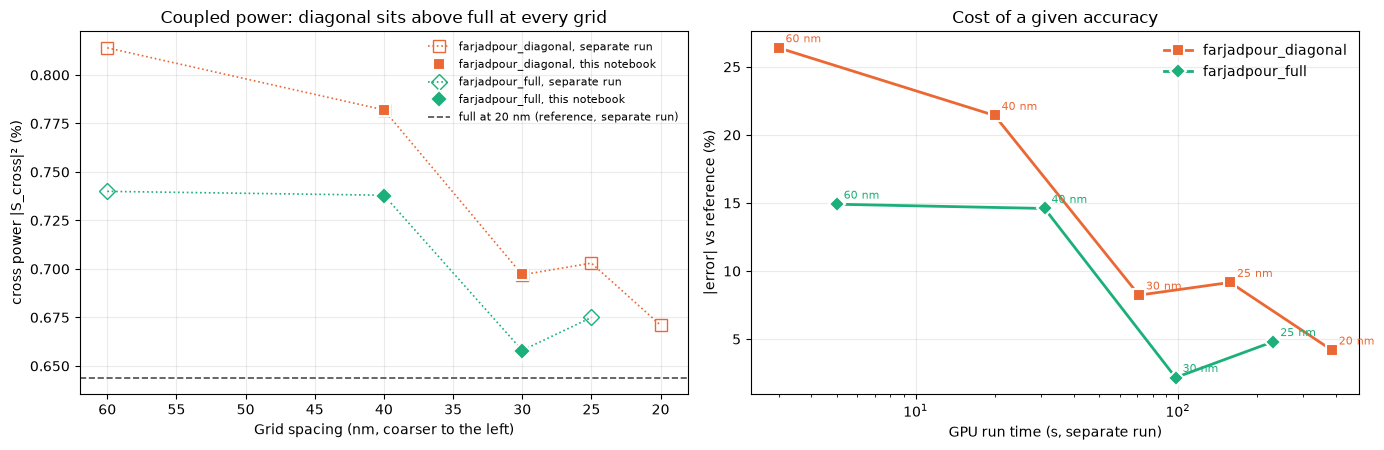

,diagonal (%),full (%),diagonal / full,diagonal vs reference (%),full vs reference (%),full / diagonal run time
grid_nm,,,,,,
30,0.697,0.658,1.061,8.3,2.1,1.39
40,0.782,0.738,1.060,21.4,14.5,1.56


In [10]:
reference_pct = 0.644  # farjadpour_full at 20 nm, separate run
# Separate GPU run of the same geometry: grid (nm) -> (cross power %, run time s, peak GB)
separate_run = {
    "farjadpour_diagonal": {60: (0.814, 3, 0.14), 40: (0.782, 20, 0.45), 30: (0.697, 71, 1.12),
                            25: (0.703, 158, 1.93), 20: (0.671, 386, 3.66)},
    "farjadpour_full": {60: (0.740, 5, 0.17), 40: (0.738, 31, 0.58), 30: (0.658, 98, 1.36),
                        25: (0.675, 231, 2.49)},
}

fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
for name in pair:
    quoted = separate_run[name]
    axs[0].plot(list(quoted), [v[0] for v in quoted.values()], ls=":", marker=markers[name], color=colors[name],
                mfc="none", ms=8, lw=1.2, label=f"{name}, separate run")
    run = coupler_data[coupler_data.smoothing == name]
    axs[0].plot(run.grid_nm, run.cross_pct, marker=markers[name], color=colors[name], ls="none", ms=9,
                mec="white", mew=1.5, label=f"{name}, this notebook")
    error = [abs(v[0] / reference_pct - 1) * 100 for v in quoted.values()]
    axs[1].plot([v[1] for v in quoted.values()], error, marker=markers[name], color=colors[name], lw=2, ms=8,
                mec="white", mew=1.5, label=name)
    for nm, (_, seconds, _), e in zip(quoted, quoted.values(), error):
        axs[1].annotate(f"{nm} nm", (seconds, e), xytext=(5, 4), textcoords="offset points", fontsize=8, color=colors[name])
axs[0].axhline(reference_pct, color="0.3", ls="--", lw=1.2, label="full at 20 nm (reference, separate run)")
axs[0].set(xlabel="Grid spacing (nm, coarser to the left)", ylabel="cross power |S_cross|² (%)",
           title="Coupled power: diagonal sits above full at every grid")
axs[0].invert_xaxis()
axs[0].legend(frameon=False, fontsize=8)
axs[1].set_xscale("log")
axs[1].set(xlabel="GPU run time (s, separate run)", ylabel="|error| vs reference (%)",
           title="Cost of a given accuracy")
axs[1].legend(frameon=False)
for ax in axs:
    ax.grid(True, alpha=0.25)
fig.tight_layout()
plt.show()

cross = coupler_data.pivot(index="grid_nm", columns="smoothing", values="cross_pct")
seconds = coupler_data.pivot(index="grid_nm", columns="smoothing", values="seconds")
display(pd.DataFrame({
    "diagonal (%)": cross[pair[0]].round(3), "full (%)": cross[pair[1]].round(3),
    "diagonal / full": (cross[pair[0]] / cross[pair[1]]).round(3),
    "diagonal vs reference (%)": (100 * (cross[pair[0]] / reference_pct - 1)).round(1),
    "full vs reference (%)": (100 * (cross[pair[1]] / reference_pct - 1)).round(1),
    "full / diagonal run time": (seconds[pair[1]] / seconds[pair[0]]).round(2),
}))

### Reading the result

Diagonal predicts 4–6% more cross power than full at the same 40–20 nm grids. Against the
20 nm full-tensor reference, full at 30 nm is 2% high, while diagonal at 30 nm is 8% high
and diagonal at 20 nm is still 4% high. Full at 30 nm runs 3.9× faster than diagonal at 20 nm.

That reference favors full tensor. Using diagonal's own 20 nm result instead gives a
smaller 1.6× saving (diagonal at 25 nm versus full at 30 nm). Both methods rise at 25 nm,
showing sensitivity to how the gap lands on the grid. These are indicative speedups,
not an independently established error bound.

An S-bend coupler, whose closest walls are nearly grid-aligned, showed only 1–2% difference
in coupling amplitude. A multimode SiN bend showed a larger method effect on mode conversion
than on total guided power. See the [measurement report](../../benchmarks/reports/CURVED_INTERFACE_SMOOTHING.md)
for those results and their limitations.
